In [22]:
#%pip install seaborn pandas scikit-learn -q

In [23]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor

In [24]:
%matplotlib inline
#Perintah untuk langsung menggambar dan menampilkan grafik langsung di halaman notebook

In [25]:
df = pd.read_csv("/lq45_data.csv")
df.head(3)

,Date,Ticker,Open,High,Low,Close
0,2024-12-05,AADI.JK,5880.733887,5880.733887,5880.733887,5880.733887
1,2024-12-06,AADI.JK,7052.458984,7052.458984,7052.458984,7052.458984
2,2024-12-09,AADI.JK,8445.264648,8445.264648,8445.264648,8445.264648


#EDA

##Cek Dataset

In [26]:
print("Kolom: ", df.columns.tolist())
print(df.shape)

Kolom:  ['Date', 'Ticker', 'Open', 'High', 'Low', 'Close']
(51313, 6)


##Struktur Data & Statistik Dasar

In [27]:
print(df.info())
print(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51313 entries, 0 to 51312
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Date    51313 non-null  object 
 1   Ticker  51313 non-null  object 
 2   Open    51313 non-null  float64
 3   High    51313 non-null  float64
 4   Low     51313 non-null  float64
 5   Close   51313 non-null  float64
dtypes: float64(4), object(2)
memory usage: 2.3+ MB
None
               Open          High           Low         Close
count  51313.000000  51313.000000  51313.000000  51313.000000
mean    3694.041367   3745.247234   3637.164718   3689.099617
std     4438.348437   4489.489174   4382.160129   4434.716281
min       50.000000     50.000000     50.000000     50.000000
25%     1083.545346   1101.680090   1065.000000   1082.367676
50%     2129.216970   2163.253886   2087.705954   2124.829102
75%     4591.892505   4645.833008   4530.536691   4585.664062
max    31502.331400  31695.449141  31091.95

##Cek type data

In [28]:
df.dtypes

,0
Date,object
Ticker,object
Open,float64
High,float64
Low,float64
Close,float64


##Mengecek missing value

In [29]:
print(df.isnull().sum().sort_values(ascending=False))
print((df.isnull().mean() * 100).round(2).sort_values(ascending=False))

Date      0
Ticker    0
Open      0
High      0
Low       0
Close     0
dtype: int64
Date      0.0
Ticker    0.0
Open      0.0
High      0.0
Low       0.0
Close     0.0
dtype: float64


In [30]:
missing = pd.DataFrame({
    "Jumlah Missing: ": (df.isnull().sum()),
    "Persentase Missing: ": ((df.isnull().sum() / df.shape[0]) * 100).round(2)
})

missing.sort_values("Persentase Missing: ", ascending=False)

,Jumlah Missing:,Persentase Missing:
Date,0,0.0
Ticker,0,0.0
Open,0,0.0
High,0,0.0
Low,0,0.0
Close,0,0.0


##Menampilkan heatmap missing value

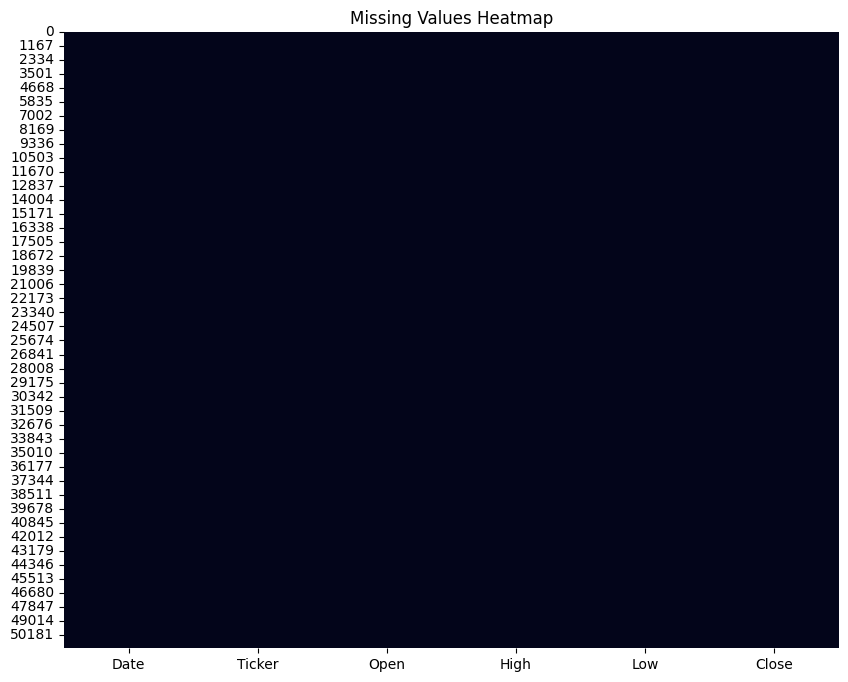

In [31]:
plt.figure(figsize=(10, 8))

sns.heatmap(df.isna(), cbar=False)

plt.title("Missing Values Heatmap")
plt.show()

##Cek duplikasi kolom

In [32]:
df.duplicated().sum()

np.int64(0)

##Nilai feature numerical

In [33]:
numerical_feature = ['Open', 'High', 'Low', 'Close']
categorical_feature = ['Ticker']

for column in categorical_feature:
  print(f"{column}: {df[column].unique()}")

Ticker: ['AADI.JK' 'ADRO.JK' 'AKRA.JK' 'AMMN.JK' 'AMRT.JK' 'ANTM.JK' 'ASII.JK'
 'BBCA.JK' 'BBNI.JK' 'BBRI.JK' 'BBTN.JK' 'BFIN.JK' 'BJTM.JK' 'BMRI.JK'
 'BREN.JK' 'BRPT.JK' 'BUKA.JK' 'CPIN.JK' 'ESSA.JK' 'EXCL.JK' 'GOTO.JK'
 'HRUM.JK' 'ICBP.JK' 'INCO.JK' 'INDF.JK' 'INKP.JK' 'INTP.JK' 'ISAT.JK'
 'ITMG.JK' 'JPFA.JK' 'KLBF.JK' 'MAPI.JK' 'MBMA.JK' 'MDKA.JK' 'MEDC.JK'
 'MIKA.JK' 'PGAS.JK' 'PTBA.JK' 'SIDO.JK' 'SMGR.JK' 'TBIG.JK' 'TLKM.JK'
 'TOWR.JK' 'UNTR.JK' 'UNVR.JK']


##Mengubah date menjadi format datetime

In [34]:
df['Date'] = pd.to_datetime(df['Date'])

df= df.sort_values(by=['Ticker', 'Date']).reset_index(drop=True)

df.head(5)

,Date,Ticker,Open,High,Low,Close
0,2024-12-05,AADI.JK,5880.733887,5880.733887,5880.733887,5880.733887
1,2024-12-06,AADI.JK,7052.458984,7052.458984,7052.458984,7052.458984
2,2024-12-09,AADI.JK,8445.264648,8445.264648,8445.264648,8445.264648
3,2024-12-10,AADI.JK,9285.369668,10059.150474,8489.480839,9086.397461
4,2024-12-11,AADI.JK,9086.397064,9241.153219,8467.372447,8489.480469


#Saham BBCA

##Menggunakan 1 saham sebagai contoh

###Filter hanya menggunakan saham BBCA saja

In [35]:
df_bbca= df[df['Ticker'] == 'BBCA.JK'].copy()

df_bbca['Date'] = pd.to_datetime(df_bbca['Date'])
df_bbca = df_bbca.sort_values('Date')

df_bbca.head(5)

,Date,Ticker,Open,High,Low,Close
7085,2021-08-13,BBCA.JK,5440.936258,5513.767689,5419.515249,5492.346680
7086,2021-08-16,BBCA.JK,5500.915039,5500.915039,5402.378399,5500.915039
7087,2021-08-18,BBCA.JK,5586.597807,5792.239444,5535.187398,5655.145020
7088,2021-08-19,BBCA.JK,5655.145020,5655.145020,5595.166209,5655.145020
7089,2021-08-20,BBCA.JK,5655.145020,5655.145020,5578.029406,5655.145020


###Plotting grafik harga close


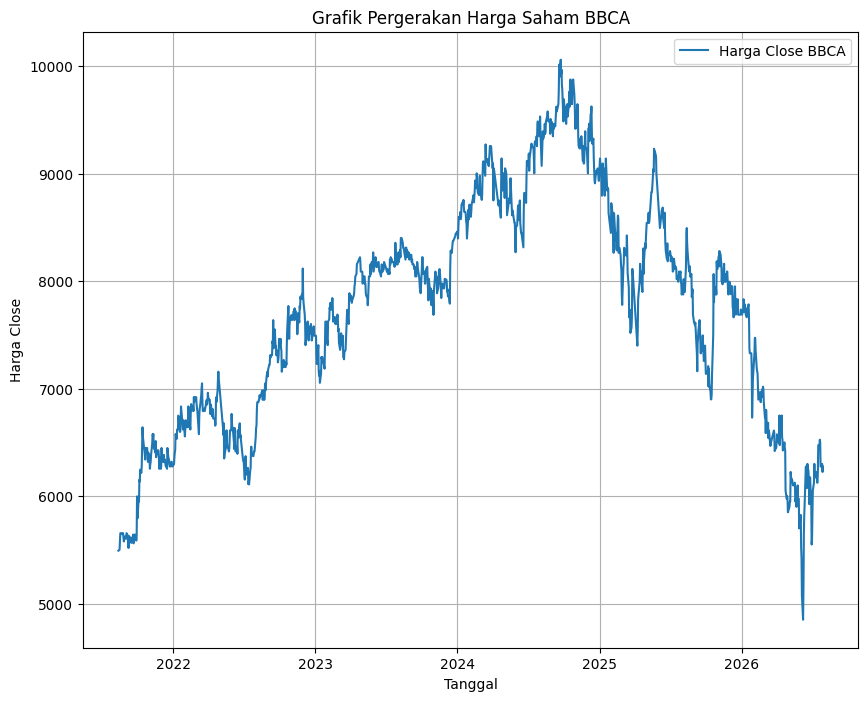

In [36]:
plt.figure(figsize=(10, 8))
plt.plot(df_bbca['Date'], df_bbca['Close'], label='Harga Close BBCA' )
plt.xlabel('Tanggal')
plt.ylabel('Harga Close')
plt.title('Grafik Pergerakan Harga Saham BBCA')
plt.legend()
plt.grid(True)
plt.show()

###Fitur

In [37]:
# Membuat kolom Lag_1 (Harga penutupan hari sebelumnya)
df_bbca['Lag_1'] = df_bbca['Close'].shift(1)

# Membuat kolom Target (Harga penutupan hari esok yang ingin diprediksi)
df_bbca['Target'] = df_bbca['Close']

#- MA_5: Rata-rata harga 5 hari terakhir
df_bbca['MA_5'] = df_bbca['Close'].rolling(window=5).mean()

#- MA_10: Rata-rata harga 20 hari terakhir
df_bbca['MA_20'] = df_bbca['Close'].rolling(window=20).mean()

# Hapus baris yang kosong akibat proses shift()
df_bbca = df_bbca.dropna()

# Tampilkan beberapa baris data teratas setelah diberi fitur tambahan
print(df_bbca[['Date', 'Lag_1', 'Target', 'MA_5', 'MA_20']].head())

           Date        Lag_1       Target         MA_5        MA_20
7104 2021-09-10  5629.440430  5586.598633  5599.450977  5611.660937
7105 2021-09-13  5586.598633  5616.587891  5596.023730  5617.872998
7106 2021-09-14  5616.587891  5608.019531  5591.739551  5623.228223
7107 2021-09-15  5608.019531  5565.176758  5601.164648  5618.729810
7108 2021-09-16  5565.176758  5569.461914  5589.168945  5614.445654


In [38]:
# 2. Tentukan Fitur (X) dan Target (y) untuk LR
x = df_bbca[['Lag_1', 'MA_5', 'MA_20']]  # Fitur masukan (harga kemarin, MA_5, MA_20)
y = df_bbca['Target']   # Target yang mau diprediksi (harga hari ini)

###Memisahkan train test split

In [39]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size= 0.2, shuffle=False)

###Panggil & uji prediksi model menggunakan linear regression

In [40]:
model = LinearRegression()
model.fit(x_train, y_train)

y_pred_lr = model.predict(x_test)

In [41]:
# 6. Evaluasi performa model
print("--- Hasil Evaluasi Model ---")
print("R-squared (Akurasi kecocokan tren):", r2_score(y_test, y_pred_lr))
print("Mean Squared Error (Besarnya error):", mean_squared_error(y_test, y_pred_lr))

# Tampilkan beberapa contoh hasil prediksi vs kenyataan sebenarnya
hasil_bandingan = pd.DataFrame({'Aktual (Asli)': y_test, 'Prediksi LR': y_pred_lr})
print("\nContoh Perbandingan Asli vs Prediksi:")
print(hasil_bandingan.head(10))

#Persentase perbedaan prediksi vs aktua(Kenyataan)
Persentase = pd.DataFrame ({
    'Aktual (asli)': y_test,
    'Prediksi LR': y_pred_lr
})
# 1. Hitung selisih mutlak (nilai absolut dari perbedaan)
hasil_bandingan['Selisih'] = abs(hasil_bandingan['Aktual (Asli)'] - hasil_bandingan['Prediksi LR'])

# 2. Hitung persentase perbedaan (%)
hasil_bandingan['Persentase_Error (%)'] = (hasil_bandingan['Selisih'] / hasil_bandingan['Aktual (Asli)']) * 100

# Tampilkan 10 baris teratas dengan kolom baru
print("\nTabel Perbandingan dengan Persentase Perbedaan:")
print(hasil_bandingan[['Aktual (Asli)', 'Prediksi LR', 'Persentase_Error (%)']].head(10))

--- Hasil Evaluasi Model ---
R-squared (Akurasi kecocokan tren): 0.967667233802663
Mean Squared Error (Besarnya error): 21141.672409985833

Contoh Perbandingan Asli vs Prediksi:
      Aktual (Asli)  Prediksi LR
8043    8137.616211  7944.541781
8044    8423.147461  8085.510718
8045    8494.529297  8271.113109
8046    8351.763672  8362.880643
8047    8280.380859  8370.778591
8048    8090.027344  8338.992102
8049    8113.821777  8226.532607
8050    8137.616211  8179.725848
8051    8042.439941  8141.044730
8052    8066.233398  8075.960851

Tabel Perbandingan dengan Persentase Perbedaan:
      Aktual (Asli)  Prediksi LR  Persentase_Error (%)
8043    8137.616211  7944.541781              2.372617
8044    8423.147461  8085.510718              4.008439
8045    8494.529297  8271.113109              2.630119
8046    8351.763672  8362.880643              0.133109
8047    8280.380859  8370.778591              1.091710
8048    8090.027344  8338.992102              3.077428
8049    8113.821777  8226

###Train test split

###Panggil & Uji menggunakan RandomForest

In [42]:
rf_model = RandomForestRegressor(n_estimators = 100, random_state= 42)
rf_model.fit(x_train, y_train)

y_pred_rf = model.predict(x_test)

###Evaluasi

In [43]:
print("--- Hasil Evaluasi Random Forest ---")
print("R-squared (Akurasi):", r2_score(y_test, y_pred_rf))
print("Mean Squared Error (MSE):", mean_squared_error(y_test, y_pred_rf))

--- Hasil Evaluasi Random Forest ---
R-squared (Akurasi): 0.967667233802663
Mean Squared Error (MSE): 21141.672409985833


In [44]:
#Tabel perbandingan lengkap dengan persentase error
hasil_banding_rf= pd.DataFrame({'Aktual (Asli)': y_test, 'Prediksi RF': y_pred_rf})

hasil_banding_rf['Selisih'] = abs(hasil_banding_rf['Aktual (Asli)'] - hasil_banding_rf['Prediksi RF'])
hasil_banding_rf['Persentase_Error (%)'] = (hasil_banding_rf['Selisih'] / hasil_banding_rf['Aktual (Asli)']) * 100

print("\nTabel Perbandingan dengan Persentase Perbedaan:")
print(hasil_banding_rf[['Aktual (Asli)', 'Prediksi RF', 'Persentase_Error (%)']].head(10))


Tabel Perbandingan dengan Persentase Perbedaan:
      Aktual (Asli)  Prediksi RF  Persentase_Error (%)
8043    8137.616211  7944.541781              2.372617
8044    8423.147461  8085.510718              4.008439
8045    8494.529297  8271.113109              2.630119
8046    8351.763672  8362.880643              0.133109
8047    8280.380859  8370.778591              1.091710
8048    8090.027344  8338.992102              3.077428
8049    8113.821777  8226.532607              1.389121
8050    8137.616211  8179.725848              0.517469
8051    8042.439941  8141.044730              1.226056
8052    8066.233398  8075.960851              0.120595


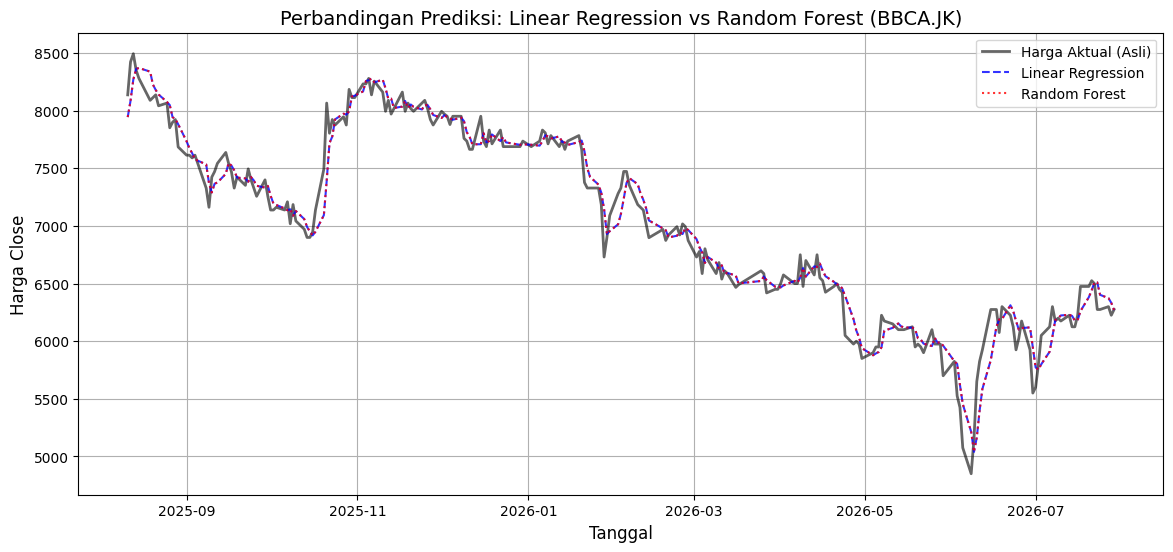

In [45]:
test_dates = df_bbca['Date'].iloc[-len(y_test):]

plt.figure(figsize=(14, 6))
plt.plot(test_dates, y_test, label='Harga Aktual (Asli)', color='black', alpha=0.6, linewidth=2)
plt.plot(test_dates, y_pred_lr, label='Linear Regression', color='blue', linestyle='--', alpha=0.8)
plt.plot(test_dates, y_pred_rf, label='Random Forest', color='red', linestyle=':', alpha=0.8)

plt.title('Perbandingan Prediksi: Linear Regression vs Random Forest (BBCA.JK)', fontsize=14)
plt.xlabel('Tanggal', fontsize=12)
plt.ylabel('Harga Close', fontsize=12)
plt.legend()
plt.grid(True)
plt.show()

#Prediksi LQ45

###Mengubah dataset LQ45 menjadi kelompok Index_Close berdasarkan 'Close'

In [46]:
lq45_index = df.groupby('Date')['Close'].mean().reset_index()
lq45_index.rename(columns={'Close': 'Index_Close'}, inplace=True)
lq45_index.sort_values('Date')
print(lq45_index.head())

        Date  Index_Close
0 2021-08-13  2840.865055
1 2021-08-16  2831.574130
2 2021-08-18  2849.433651
3 2021-08-19  2788.293489
4 2021-08-20  2799.690344


###Plotting Pergerakan Harga

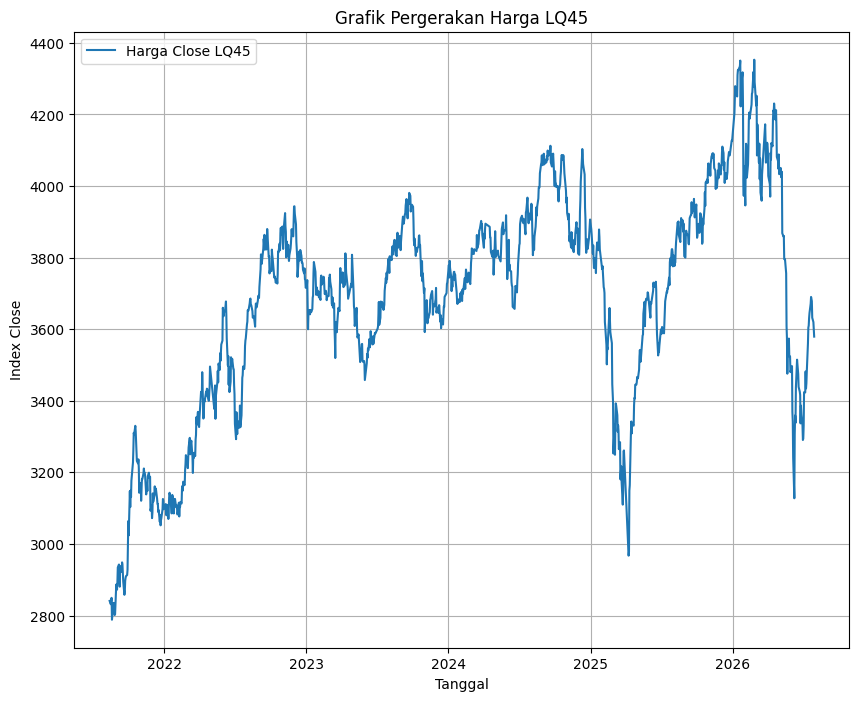

In [47]:
plt.figure(figsize=(10, 8))
plt.plot(lq45_index['Date'], lq45_index['Index_Close'], label='Harga Close LQ45' )
plt.xlabel('Tanggal')
plt.ylabel('Index Close')
plt.title('Grafik Pergerakan Harga LQ45')
plt.legend()
plt.grid(True)
plt.show()

###Fitur

In [48]:
lq45_index['Lag_1']= lq45_index['Index_Close'].shift(1)
lq45_index['Target'] = lq45_index['Index_Close']
lq45_index['MA_5'] = lq45_index['Index_Close'].rolling(window=5).mean()
lq45_index['MA_20'] = lq45_index['Index_Close'].rolling(window=20).mean()

lq45_index = lq45_index.dropna()

print(lq45_index[['Date', 'Lag_1', 'Target', 'MA_5', 'MA_20']].head())

         Date        Lag_1       Target         MA_5        MA_20
19 2021-09-10  2938.084860  2936.506986  2923.975921  2864.741994
20 2021-09-13  2936.506986  2922.329755  2919.933118  2868.815229
21 2021-09-14  2922.329755  2948.448668  2925.193198  2874.658956
22 2021-09-15  2948.448668  2941.287157  2937.331485  2879.251631
23 2021-09-16  2941.287157  2917.590398  2933.232593  2885.716476


###Prediksi LR

In [49]:
# 1. Tentukan Fitur (X) dan Target (y) khusus untuk LQ45
x_lq45 = lq45_index[['Lag_1', 'MA_5', 'MA_20']]
y_lq45 = lq45_index['Target']

# 2. Split data dengan urutan variabel yang benar
x_train_lq45, x_test_lq45, y_train_lq45, y_test_lq45 = train_test_split(x_lq45, y_lq45, test_size=0.2, shuffle=False)

# 3. Buat dan latih model Linear Regression khusus LQ45
model_lq45 = LinearRegression()
model_lq45.fit(x_train_lq45, y_train_lq45)

# 4. Lakukan prediksi pada data test LQ45
y_pred_lr_lq45 = model_lq45.predict(x_test_lq45)

# 5. Evaluasi performa model
print("--- Hasil Evaluasi Model LQ45 ---")
print("R-squared (Akurasi kecocokan tren):", r2_score(y_test_lq45, y_pred_lr_lq45))
print("Mean Squared Error (Besarnya error):", mean_squared_error(y_test_lq45, y_pred_lr_lq45))

# 6. Tampilkan beberapa contoh hasil prediksi vs kenyataan sebenarnya
hasil_bandingan_lq45 = pd.DataFrame({'Aktual (Asli)': y_test_lq45, 'Prediksi LQ45': y_pred_lr_lq45})

# 7. Hitung selisih mutlak dan persentase perbedaan (%)
hasil_bandingan_lq45['Selisih'] = abs(hasil_bandingan_lq45['Aktual (Asli)'] - hasil_bandingan_lq45['Prediksi LQ45'])
hasil_bandingan_lq45['Persentase_Error (%)'] = (hasil_bandingan_lq45['Selisih'] / hasil_bandingan_lq45['Aktual (Asli)']) * 100

print("\nTabel Perbandingan dengan Persentase Perbedaan:")
print(hasil_bandingan_lq45[['Aktual (Asli)', 'Prediksi LQ45', 'Persentase_Error (%)']].head(10))

--- Hasil Evaluasi Model LQ45 ---
R-squared (Akurasi kecocokan tren): 0.9683053612146678
Mean Squared Error (Besarnya error): 2292.043024719656

Tabel Perbandingan dengan Persentase Perbedaan:
     Aktual (Asli)  Prediksi LQ45  Persentase_Error (%)
958    3886.945053    3837.664658              1.267844
959    3898.470199    3871.572522              0.689955
960    3895.523338    3889.339088              0.158753
961    3900.891669    3896.305290              0.117573
962    3863.297820    3900.552249              0.964317
963    3843.498428    3876.024474              0.846261
964    3886.236407    3863.786364              0.577681
965    3910.397299    3886.327079              0.615544
966    3896.809220    3897.433678              0.016025
967    3904.259802    3894.817850              0.241837


###Prediksi RF

In [50]:
# 1. Tentukan Fitur (X) dan Target (y) khusus untuk LQ45
x_lq45 = lq45_index[['Lag_1', 'MA_5', 'MA_20']]
y_lq45 = lq45_index['Target']

# 2. Split data dengan urutan variabel yang benar
x_train_lq45, x_test_lq45, y_train_lq45, y_test_lq45 = train_test_split(x_lq45, y_lq45, test_size=0.2, shuffle=False)

# 3. Buat dan latih model Linear Regression khusus LQ45
model_lq45 = RandomForestRegressor(n_estimators = 100, random_state= 42)
model_lq45.fit(x_train_lq45, y_train_lq45)

# 4. Lakukan prediksi pada data test LQ45
y_pred_rf_lq45 = model_lq45.predict(x_test_lq45)

# 5. Evaluasi performa model
print("--- Hasil Evaluasi Model LQ45 ---")
print("R-squared (Akurasi kecocokan tren):", r2_score(y_test_lq45, y_pred_rf_lq45))
print("Mean Squared Error (Besarnya error):", mean_squared_error(y_test_lq45, y_pred_rf_lq45))

# 6. Tampilkan beberapa contoh hasil prediksi vs kenyataan sebenarnya
hasil_bandingan_lq45 = pd.DataFrame({'Aktual (Asli)': y_test_lq45, 'Prediksi LQ45': y_pred_rf_lq45})

# 7. Hitung selisih mutlak dan persentase perbedaan (%)
hasil_bandingan_lq45['Selisih'] = abs(hasil_bandingan_lq45['Aktual (Asli)'] - hasil_bandingan_lq45['Prediksi LQ45'])
hasil_bandingan_lq45['Persentase_Error (%)'] = (hasil_bandingan_lq45['Selisih'] / hasil_bandingan_lq45['Aktual (Asli)']) * 100

print("\nTabel Perbandingan dengan Persentase Perbedaan:")
print(hasil_bandingan_lq45[['Aktual (Asli)', 'Prediksi LQ45', 'Persentase_Error (%)']].head(10))

--- Hasil Evaluasi Model LQ45 ---
R-squared (Akurasi kecocokan tren): 0.9155010434268533
Mean Squared Error (Besarnya error): 6110.662605159573

Tabel Perbandingan dengan Persentase Perbedaan:
     Aktual (Asli)  Prediksi LQ45  Persentase_Error (%)
958    3886.945053    3850.924143              0.926715
959    3898.470199    3876.296161              0.568788
960    3895.523338    3883.322987              0.313189
961    3900.891669    3894.956400              0.152152
962    3863.297820    3901.916379              0.999627
963    3843.498428    3862.115847              0.484387
964    3886.236407    3851.825430              0.885458
965    3910.397299    3879.623498              0.786974
966    3896.809220    3891.726991              0.130420
967    3904.259802    3902.625733              0.041853


###Plotting

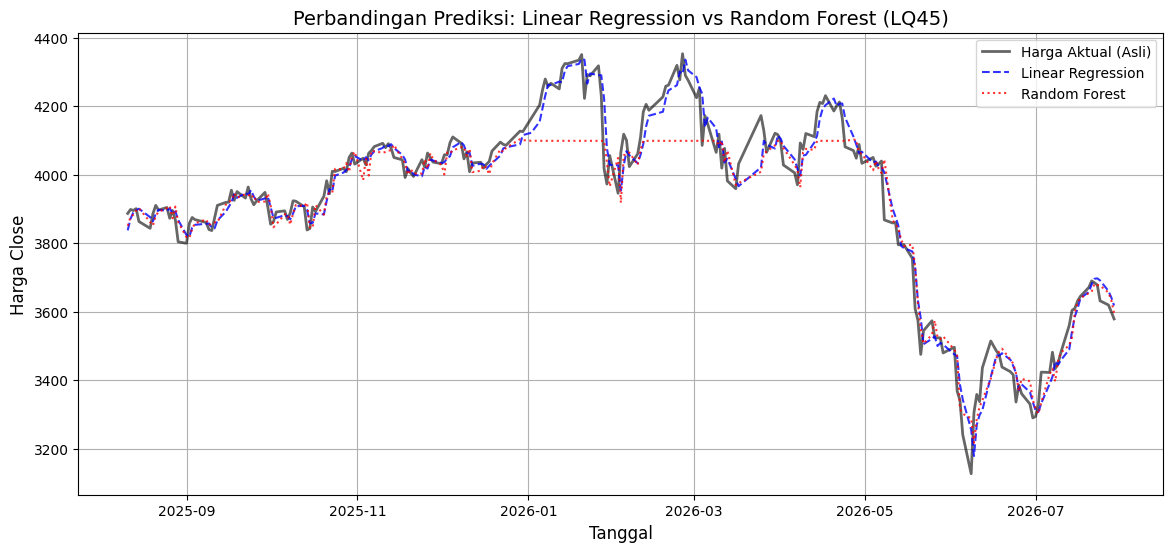

In [51]:
test_dates = lq45_index['Date'].iloc[-len(y_test):]

plt.figure(figsize=(14, 6))
plt.plot(test_dates, y_test_lq45, label='Harga Aktual (Asli)', color='black', alpha=0.6, linewidth=2)
plt.plot(test_dates, y_pred_lr_lq45, label='Linear Regression', color='blue', linestyle='--', alpha=0.8)
plt.plot(test_dates, y_pred_rf_lq45, label='Random Forest', color='red', linestyle=':', alpha=0.8)

plt.title('Perbandingan Prediksi: Linear Regression vs Random Forest (LQ45)', fontsize=14)
plt.xlabel('Tanggal', fontsize=12)
plt.ylabel('Harga Close', fontsize=12)
plt.legend()
plt.grid(True)
plt.show()

#MAE,RMSE,MAPE

In [54]:
# Asumsikan y_test adalah data aktual dan y_pred adalah hasil prediksi model
mae_lr = mean_absolute_error(y_test, y_pred_lr_lq45)
rmse_lr = mean_squared_error(y_test, y_pred_lr_lq45)
mape_lr = np.mean(np.abs((y_test - y_pred_lr_lq45) / y_test)) * 100
print("===== Evaluasi Linear Reggresion =====")
print(f"Mean Squared Error Linear Regression: {mae_lr:.2f}")
print(f"Root Mean Squared Error Linear Regression: {rmse_lr:.2f}")
print(f"Mean Absolute Percentage Error Linear Regression: {mape_lr:.2f}")

mae_rf = mean_absolute_error(y_test, y_pred_rf_lq45)
rmse_rf = mean_squared_error(y_test, y_pred_rf_lq45)
mape_rf = np.mean(np.abs((y_test - y_pred_rf_lq45) / y_test)) * 100
print("===== Evaluasi Random Forest =====")
print(f"Mean Squared Error Random Forest: {mae_rf:.2f}")
print(f"Root Mean Squared Error Random Forest: {rmse_rf:.2f}")
print(f"Mean Absolute Percentage Error Random Forest: {mape_rf:.2f}")

===== Evaluasi Linear Reggresion =====
Mean Squared Error Linear Regression: 3101.18
Root Mean Squared Error Linear Regression: 10103050.57
Mean Absolute Percentage Error Linear Regression: 43.66
===== Evaluasi Random Forest =====
Mean Squared Error Random Forest: 3127.05
Root Mean Squared Error Random Forest: 10258676.08
Mean Absolute Percentage Error Random Forest: 44.02
